## GPU code

Devices: [CudaDevice(id=0)]
GPU runtime: 0.033 s


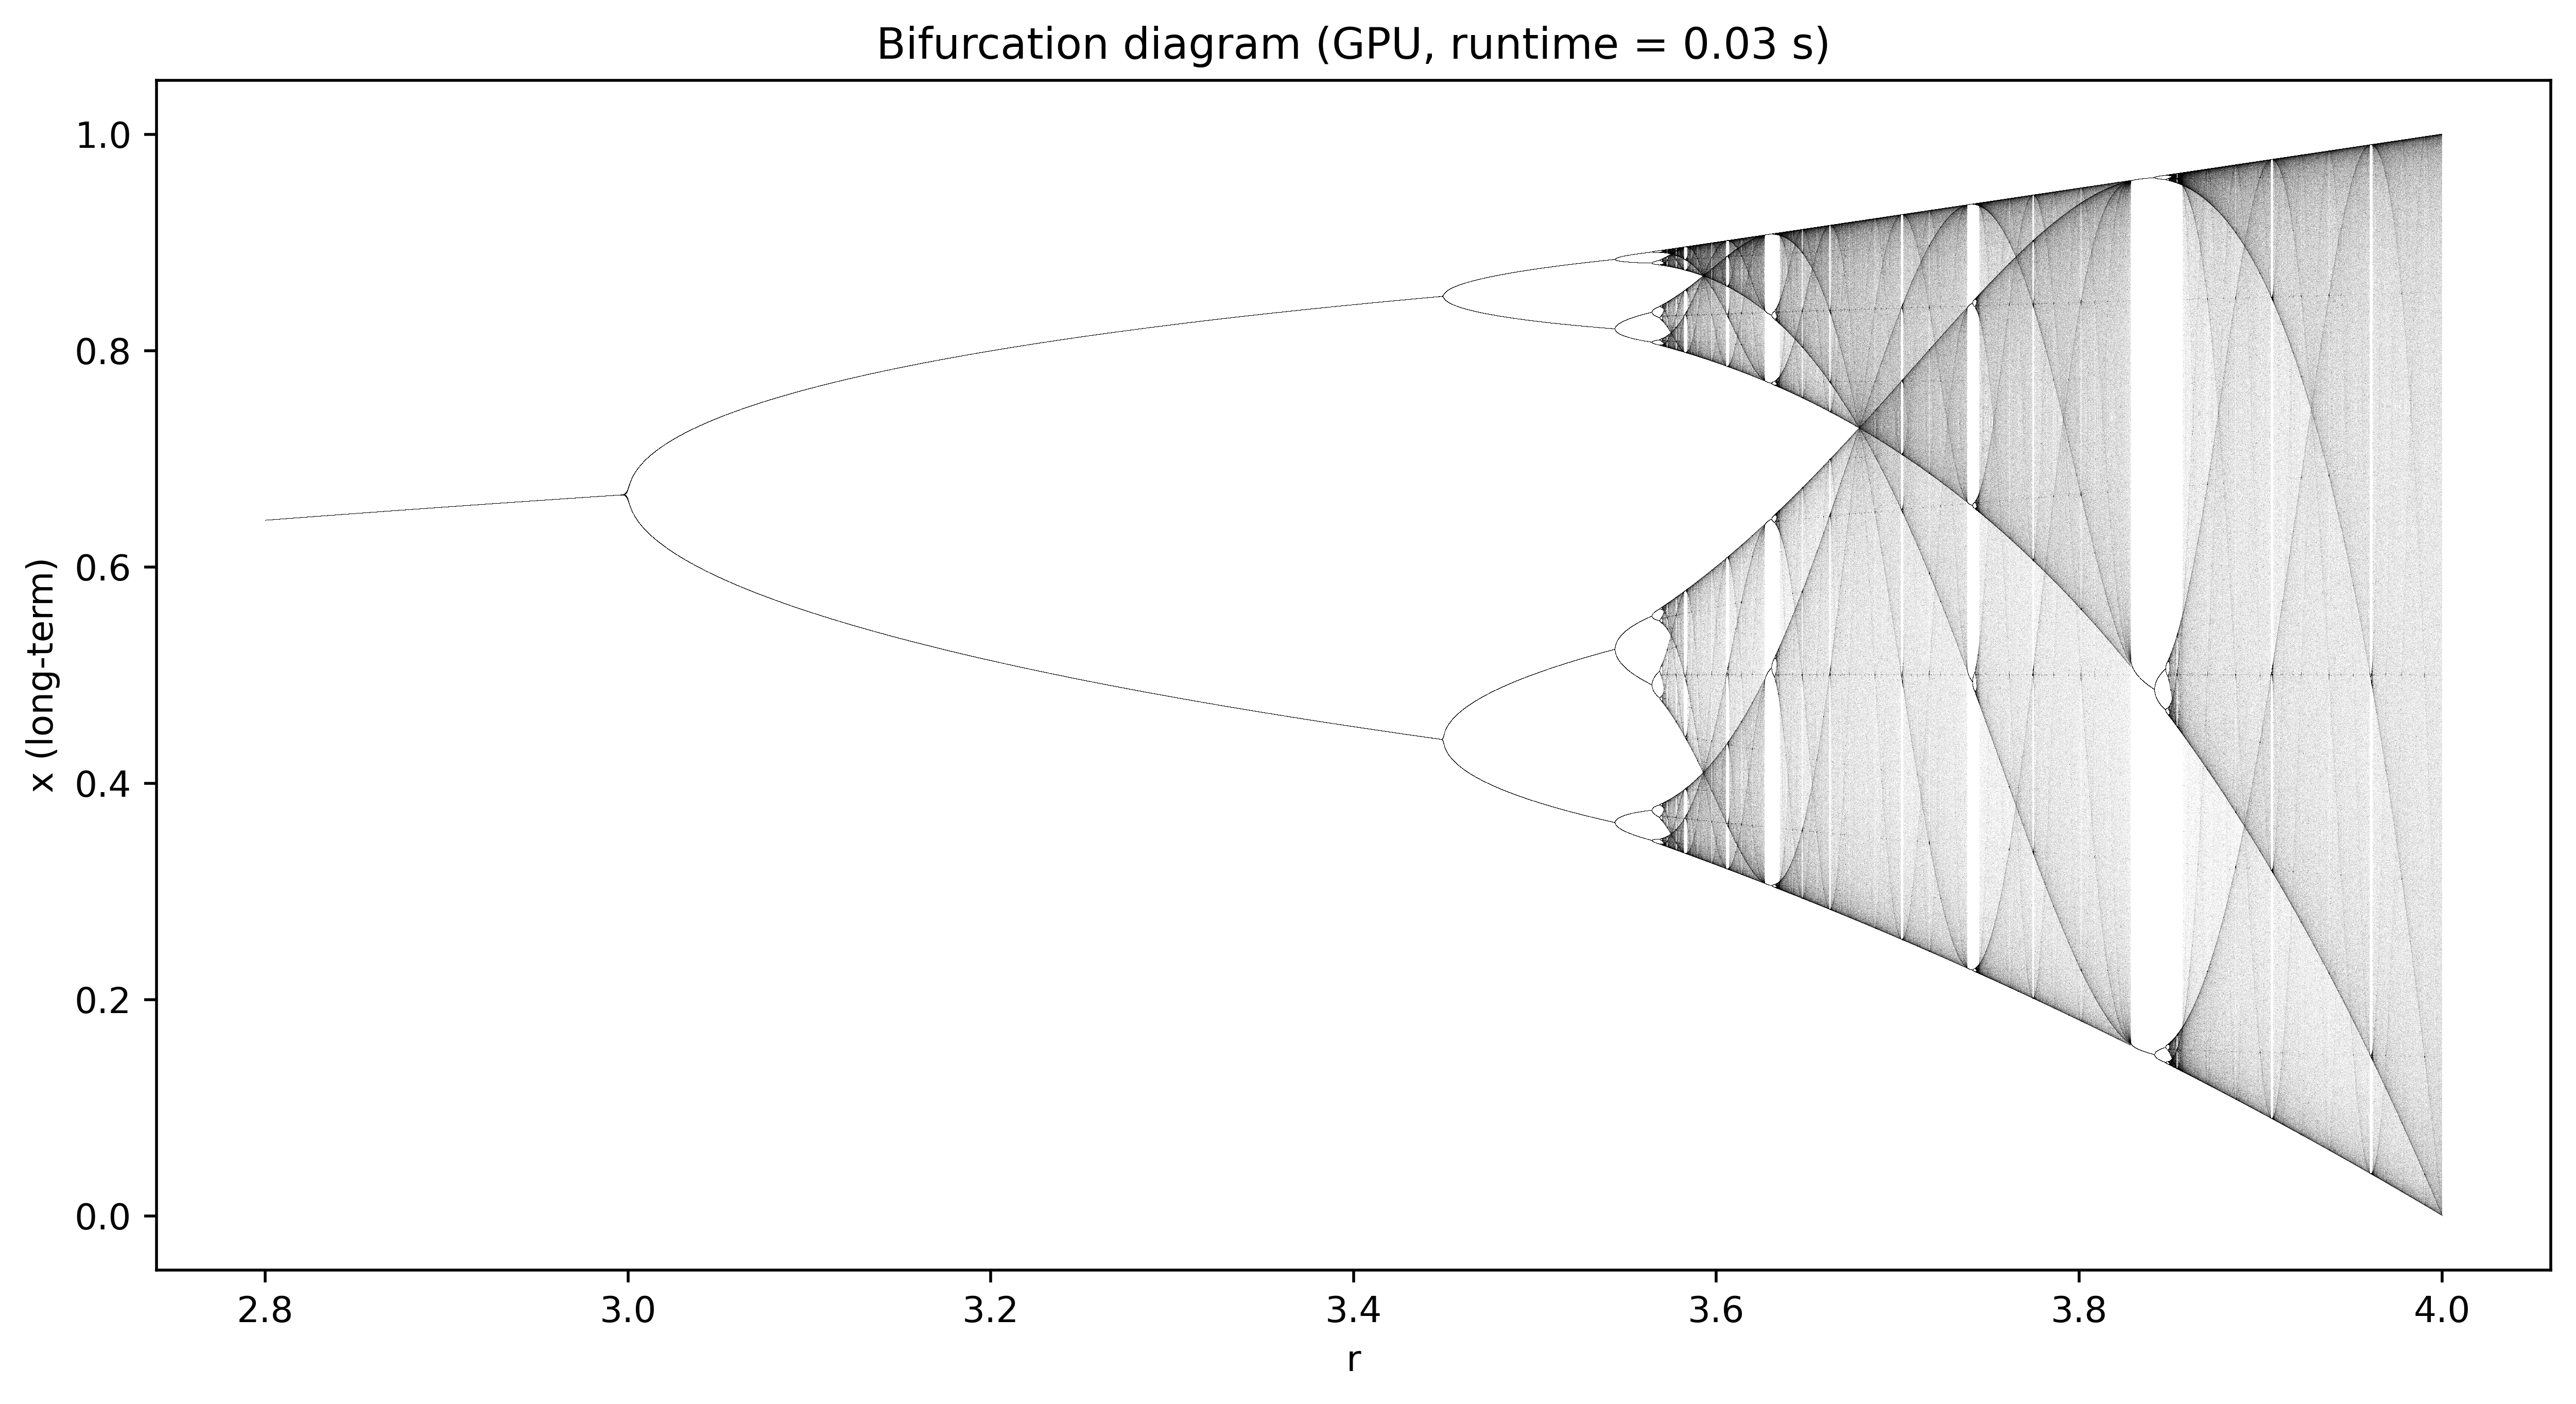

In [2]:
import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 500

print("Devices:", jax.devices())

r_values_np = np.linspace(2.8, 4.0, 50000)
n_iterations = 2000
n_last = 500

r_values_jax = jnp.array(r_values_np)

# Single-r iteration
def logistic_map_single(r, x0=0.5, n_iter=n_iterations):
    def body(x, _):
        x_new = r * x * (1 - x)
        return x_new, x_new
    _, xs = jax.lax.scan(body, x0, None, length=n_iter)
    return xs

# vmap: run ALL r values simultaneously
logistic_batched = jax.jit(jax.vmap(logistic_map_single))

# Warm-up
_ = logistic_batched(r_values_jax).block_until_ready()

# Timed run
t0 = time.time()
xs_all = logistic_batched(r_values_jax)
xs_all.block_until_ready()
t_gpu = time.time() - t0
print(f"GPU runtime: {t_gpu:.3f} s")

xs_all_np = np.array(xs_all)[:, -n_last:]
r_plot = np.repeat(r_values_np, n_last)
x_plot = xs_all_np.flatten()

plt.figure(figsize=(12, 6))
plt.plot(r_plot, x_plot, ',k', markersize=0.05, alpha=0.05)
plt.xlabel("r")
plt.ylabel("x (long-term)")
plt.title(f"Bifurcation diagram (GPU, runtime = {t_gpu:.2f} s)")
plt.show()